/opt/anaconda3/envs/av_risk/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: mps
Initializing Mask2Former from 'facebook/mask2former-swin-small-cityscapes-semantic'...


Loading weights: 100%|██████████| 758/758 [00:00<00:00, 6359.28it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-small-cityscapes-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MI


EVALUATING MODEL: Mask2Former (Swin-Small)

--- Quantitative Results: Mask2Former (Swin-Small) ---
* Valid Samples Evaluated : 100
* Model Parameters        : 68.73 M
* Avg Latency             : 198.36 ms
* Median Latency          : 196.86 ms
* Average FPS             : 5.04
* Pixel Accuracy          : 94.14%
* Mean IoU (mIoU)         : 49.77%
----------------------------------------------


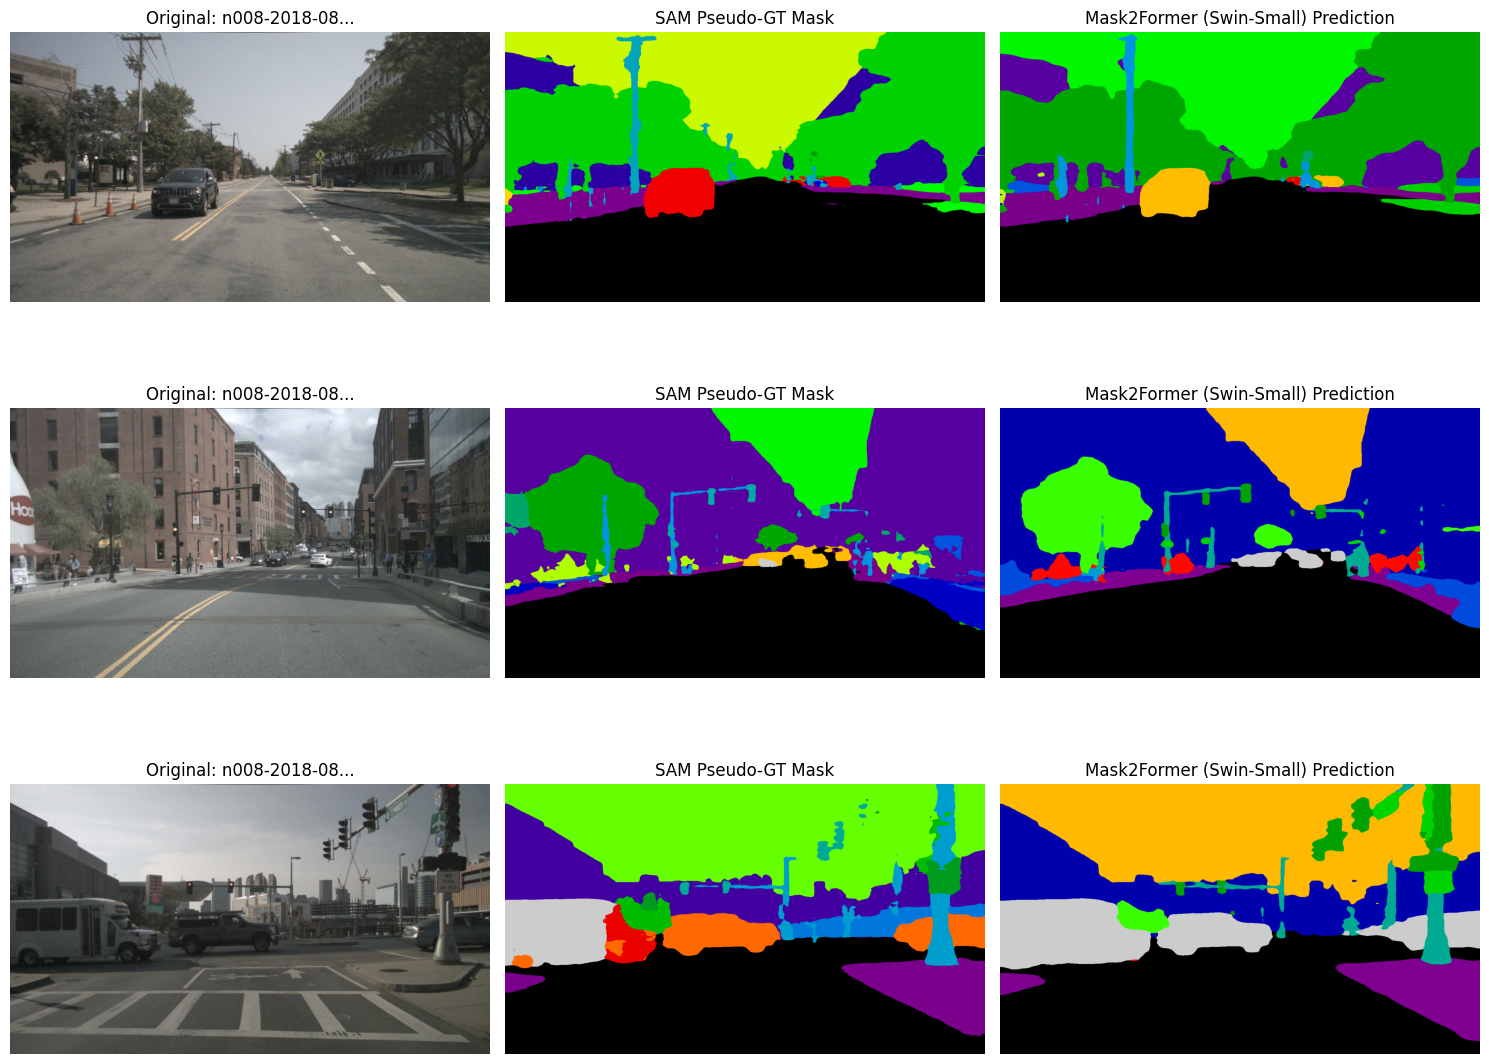

In [1]:
import time
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from transformers import Mask2FormerForUniversalSegmentation, AutoImageProcessor

# 0. Define Required Paths & Device Setup
cam_front_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/v1.0-mini/samples/CAM_FRONT/")
benchmark_images = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
gt_output_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/results/pseudo_ground_truth")

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Initialize Mask2Former from Hugging Face (Swin-Small backbone fine-tuned on Cityscapes)
model_id = "facebook/mask2former-swin-small-cityscapes-semantic"
print(f"Initializing Mask2Former from '{model_id}'...")
processor = AutoImageProcessor.from_pretrained(model_id)
mask2former_model = Mask2FormerForUniversalSegmentation.from_pretrained(model_id)

# 2. Comprehensive Evaluation & Visualization Function for Mask2Former
def evaluate_and_visualize_mask2former(
    model_name, 
    model, 
    processor,
    image_paths, 
    gt_dir, 
    device, 
    num_classes=19
):
    model.eval()
    model.to(device)

    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    latencies = []
    confusion_matrix = np.zeros((num_classes, num_classes))
    valid_samples = []

    print(f"\n==============================================")
    print(f"EVALUATING MODEL: {model_name}")
    print(f"==============================================")

    with torch.no_grad():
        # Warmup run
        dummy_image = Image.new("RGB", (640, 384), color=(128, 128, 128))
        dummy_inputs = processor(images=dummy_image, return_tensors="pt").to(device)
        _ = model(**dummy_inputs)

        for img_path in image_paths:
            mask_path = gt_dir / f"{img_path.stem}_mask.png"
            if not mask_path.exists():
                continue
            
            image = Image.open(img_path).convert("RGB")
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
            
            # Process image using Hugging Face processor
            inputs = processor(images=image, return_tensors="pt").to(device)

            start_time = time.time()
            outputs = model(**inputs)
            
            if device.type == "mps":
                torch.mps.synchronize()
            elif device.type == "cuda":
                torch.cuda.synchronize()
                
            elapsed = time.time() - start_time
            latencies.append(elapsed)

            # Post-process semantic segmentation outputs back to original image size
            predicted_semantic_map = processor.post_process_semantic_segmentation(
                outputs, target_sizes=[image.size[::-1]]
            )[0]
            
            pred = predicted_semantic_map.cpu().numpy()

            if pred.shape != gt_mask.shape:
                gt_mask = np.array(
                    Image.fromarray(gt_mask.astype(np.uint8)).resize(
                        (pred.shape[1], pred.shape[0]), Image.NEAREST
                    )
                )

            mask = (gt_mask >= 0) & (gt_mask < num_classes)
            confusion_matrix += np.bincount(
                num_classes * gt_mask[mask].astype(int) + pred[mask].astype(int),
                minlength=num_classes ** 2,
            ).reshape(num_classes, num_classes)

            valid_samples.append((img_path, gt_mask, pred))

    if not latencies:
        print("[Error] No matching ground truth masks found. Please check file paths.")
        return None

    avg_lat = np.array(latencies).mean()
    med_lat = np.median(np.array(latencies))
    avg_fps = 1.0 / avg_lat

    intersection = np.diag(confusion_matrix)
    union = confusion_matrix.sum(axis=1) + confusion_matrix.sum(axis=0) - intersection
    per_class_iou = np.divide(
        intersection, union, out=np.zeros_like(intersection, dtype=float), where=union != 0
    )
    mIoU = np.nanmean(per_class_iou)

    total_correct = np.sum(intersection)
    total_pixels = np.sum(confusion_matrix)
    pixel_accuracy = (total_correct / total_pixels) if total_pixels > 0 else 0.0

    print(f"\n--- Quantitative Results: {model_name} ---")
    print(f"* Valid Samples Evaluated : {len(valid_samples)}")
    print(f"* Model Parameters        : {total_params:.2f} M")
    print(f"* Avg Latency             : {avg_lat * 1000:.2f} ms")
    print(f"* Median Latency          : {med_lat * 1000:.2f} ms")
    print(f"* Average FPS             : {avg_fps:.2f}")
    print(f"* Pixel Accuracy          : {pixel_accuracy * 100:.2f}%")
    print(f"* Mean IoU (mIoU)         : {mIoU * 100:.2f}%")
    print(f"----------------------------------------------")

    if valid_samples:
        viz_samples = random.sample(valid_samples, min(3, len(valid_samples)))
        fig, axes = plt.subplots(len(viz_samples), 3, figsize=(15, 4 * len(viz_samples)))
        
        if len(viz_samples) == 1:
            axes = np.expand_dims(axes, 0)

        for idx, (img_p, gt, pred) in enumerate(viz_samples):
            orig_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)

            axes[idx, 0].imshow(orig_img)
            axes[idx, 0].set_title(f"Original: {img_p.name[:12]}...")
            axes[idx, 0].axis("off")

            axes[idx, 1].imshow(gt, cmap="nipy_spectral")
            axes[idx, 1].set_title("SAM Pseudo-GT Mask")
            axes[idx, 1].axis("off")

            axes[idx, 2].imshow(pred, cmap="nipy_spectral")
            axes[idx, 2].set_title(f"{model_name} Prediction")
            axes[idx, 2].axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "Model": model_name,
        "Params (M)": round(total_params, 2),
        "Avg Latency (ms)": round(avg_lat * 1000, 2),
        "FPS": round(avg_fps, 2),
        "Pixel Acc (%)": round(pixel_accuracy * 100, 2),
        "mIoU (%)": round(mIoU * 100, 2)
    }

# 3. Execute Pipeline for Mask2Former
mask2former_metrics = evaluate_and_visualize_mask2former(
    model_name="Mask2Former (Swin-Small)",
    model=mask2former_model,
    processor=processor,
    image_paths=benchmark_images,
    gt_dir=gt_output_dir,
    device=device
)